# Phase 7 — The walk-forward evaluation

**Goal.** Run the strategy the way it would have run in real time, then test it honestly. At every rebalance the walk-forward re-screens (at year-ends), refits, forecasts, sizes and trades, using only data up to that close. The primary test, fixed before the data, is read on its own. The other 191 variants are read only through p-values adjusted for having tried 192 things. **Development sample only (to 2018).** The 2019+ holdout is never loaded.

### Key findings

1. **The primary test reads "inconclusive": a Sharpe gain of +0.01.**
   - Timed 0.75 against buy-and-hold's 0.73 over 276 months (1984, and 1997–2018), p = 0.47.
   - The 95% bounds run from −0.28 to +0.31, and the test could only have detected a gain of about 0.45.
   - The CER is lower than buy-and-hold's (3.5% against 4.1%), and the placebo fails (the real α beats 86% of shuffled forecasts, not 95%).
2. **No variant beats buy-and-hold after adjusting for 192 tries.**
   - 185 of the 192 gains are positive, but only one has a raw p below 5% (0.045). After adjustment its p is 0.32 (Romano-Wolf) and 1.0 (Holm).
   - The best variant's deflated Sharpe ratio is 0.67, against a bar of 0.95.
3. **Twelve months decide all of this (information, added after the run).** In 1984 the screen held the market alone, at 19% volatility. From 1997 it held mixes at 4–6%. Pooled Sharpe ratios weight months by their variance, so 1984 outweighs the other 264 months:
   - From 1997 to 2018 alone, the primary's gain is **+0.30** (p 0.012), and **65 of 192** variants survive Romano-Wolf.
   - With 1984 in, the gain is +0.01 and none survive.
   - The pre-registered result stands. The rule that produced it needs your decision before the holdout (Section 9).
4. **What made Phase 6's edge was the asset list, not the years.** Phase 6's fixed book (market, momentum and BAB from 1950) still reads "edge", +0.36. On the primary's own 276 months it gains **+0.61**. The real-time screen held fewer, later and different assets: no momentum before 2010, profitability for 14 years, and the market alone in 1984.
5. **Q3: no forecast beats rolling RV.** None of the 168 model-against-M0 comparisons survives Romano-Wolf, and every model's median gain over M0 is slightly negative (−0.01 to −0.03).
6. **Q4: accuracy does not explain value.** Rolling RV is the least accurate model, the only one outside the MCS, and HAR-X the most accurate. Yet the rank correlation between accuracy and Sharpe ratio is −0.05.
7. **Two things timing reliably does, in every variant.** It cuts the maximum drawdown in all 192 variants (−19% against −34% for the primary), and it raises the Sortino ratio in 190. That comes from running at lower volatility (5.1% against 7.4%, median), which is also why the CER test finds no gain anywhere.
8. **The ETF track is too short to read.** SPY timed alone gains +0.17 after costs over 1997–2018, "inconclusive" (p 0.13, minimum detectable 0.37). The SPY + MTUM book has 20 months. The holdout is their test.

### How to read this notebook

Sections 1–2 are the rules and what the walk-forward holds. Section 3 is the primary test, Sections 4–6 the family, Q3 and Q4. Section 7 covers the other books, Section 8 is the one results table, and Section 9 is what 1984 does and the decisions it raises. Every table and figure reads what `python -m src.walkforward.build` wrote; one cell rebuilds the primary through the code to show that it matches.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

from src import engine as e
from src import models as md
from src import walkforward as wf
from src.config import FACTORS, PROCESSED_DIR, REPORTS_DIR
from src.data.load import load_dev
from src.engine import evaluation as ev, execution
from src.walkforward import runs, screened, stats

pd.set_option("display.float_format", "{:,.4f}".format, "display.max_columns", 40, "display.width", 220,
              "display.max_colwidth", None, "display.max_rows", 250)

BLUE, AMBER, PURPLE = "#2a78d6", "#eda100", "#4a3aa7"                  # Phase 2-6's first three hues
RED, MID = "#e34948", "#f0efec"                                        # the diverging pair's warm pole and gray midpoint
LIGHT, DARK = "#86b6ef", "#1c5cab"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "lines.linewidth": 1.5, "font.size": 8.5, "axes.titlesize": 9.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
DIVERGING = LinearSegmentedColormap.from_list("gain", [RED, MID, BLUE])
SEQUENTIAL = LinearSegmentedColormap.from_list("weight", ["#cde2fb", "#2a78d6", "#0d366b"])
NAMES = {"inv_var": "inverse variance", "inv_vol": "inverse volatility", "down_vol": "downside volatility",
         "equal": "equal", "shrunk_mv": "shrunk mean-variance", "monthly": "monthly", "weekly": "weekly"}

# Everything below reads what `python -m src.walkforward.build` wrote.
RESULTS = pd.read_csv(REPORTS_DIR / "phase7_results.csv")
PRIMARY_ROW = RESULTS.iloc[0]
FAMILY = RESULTS.iloc[1:].set_index(["model", "rule", "mix", "freq"])
VS_M0 = pd.read_csv(REPORTS_DIR / "phase7_vs_m0.csv", index_col=[0, 1, 2, 3])
Q4 = pd.read_csv(REPORTS_DIR / "phase7_q4.csv", index_col=0)
TRACKS = pd.read_csv(REPORTS_DIR / "phase7_tracks.csv", index_col=0)
SUMMARY = pd.read_csv(REPORTS_DIR / "phase7_summary.csv", index_col=0)["value"]
def _number(v):
    try:
        return float(v)
    except ValueError:
        return v                                                     # dates and names stay text
SUMMARY = SUMMARY.map(_number)
SCREEN = pd.read_csv(REPORTS_DIR / "phase7_screen.csv", index_col=[0, 1], parse_dates=[0])
RECIPES = pd.read_csv(REPORTS_DIR / "phase7_recipes.csv", index_col=[0, 1], parse_dates=[0])
RUNS = pd.read_parquet(PROCESSED_DIR / "phase7_runs.parquet")
PRIMARY_RUN = pd.read_parquet(PROCESSED_DIR / "phase7_primary.parquet").set_index("month")
PLACEBO = pd.read_parquet(PROCESSED_DIR / "phase7_placebo.parquet")["alpha_shuffled"]
panel = load_dev()
print(f"{len(FAMILY)} variants on {int(SUMMARY['common_months'])} common months, "
      f"{SUMMARY['common_first']} to {SUMMARY['common_last']}")

192 variants on 276 common months, 1984-01 to 2018-12


## 1. The rules

All of them were fixed in PREREGISTRATION Entry 6 before any walk-forward result. The four calls in the first table are yours (2026-10-19). Entry 6 marks the rest that are my choices.

### What happens at each rebalance

Everything uses data up to that close, and nothing after it:

| Step | What | When |
|---|---|---|
| Screen | Phase 3's screen on all seven factors; keep those passing filters 1, 3 and 6 (level φ), with 120 months of history | every year-end |
| Recipe | Phase 4: drop duplicates (ρ > +0.7), then weight the survivors by each of the four mixes from the last 10 years | every year-end |
| Forecast | the variance of the mix held next period: each of the eight Phase 6 models, refit on Phase 6's schedule | every rebalance |
| Size | $w_t = \min(c_t \times \text{signal}_t,\ 1.5)$, with $c_t$ matched to buy-and-hold's past volatility in real time | every rebalance |
| Trade | at that close; the new position earns from the next trading day | every rebalance |
| Record | what the next period earns, for the timed run and for buy-and-hold (the same book at size 1) | every period |

**Your four calls.**

| Question | Call |
|---|---|
| Which assets the primary book holds | the real-time screen above, on all seven factors. Filters 4 and 5 judge an ETF and cannot run before the ETFs exist, so the paper track skips them and stays an upper bound |
| Level or log φ in filter 1 | level, as written |
| What to hold when nothing passes, or before $c_t$ exists | cash, in both runs; those months are not scored |
| Assets that flip in and out | no rule: hold what passes |

**Initial training.** As in Cederburg et al., the first 10 years of each series train the models. The screen needs 120 months of a factor, the models make their first forecast at the end of the mix's 120th month, and $c_t$ then needs 120 monthly pairs (520 weekly ones).

### The primary test stands alone

It was fixed before the data, so its p-value is read as is:

- **Specification.** The screened book, inverse-volatility mix, M3 GJR-GARCH (frozen in Phase 6), inverse-variance timing, monthly, cap 1.5, no costs.
- **Statistic and test.** Entry 3's Sharpe gain over buy-and-hold, one-sided at 5%, by the Ledoit-Wolf (2008) delta method with a Newey-West covariance.
- **Readings.** **Edge** if it rejects; **no meaningful edge** if the 95% upper bound is below 0.10 a year; **inconclusive** otherwise.

Why not Jobson-Korkie: it assumes normal, independent returns, and these have fat tails and volatility clustering, the very thing the strategy exploits.

### Every variant, with honest error control

**8 forecasts × 3 timing rules × 4 mixes × 2 rebalancing frequencies = 192 variants.** The primary is one of them. If all 192 were useless and independent, each tested at 5%, the chance that at least one looks significant would be

$$1 - 0.95^{192} = 1 - e^{192 \ln 0.95} \approx 1 - e^{-9.85} \approx 0.99995.$$

The variants are correlated, so the true figure is lower, but it is still far above 5%. So the family is read only through adjusted p-values:

- **Romano-Wolf stepdown.** It holds the chance of any false positive at 5%. Its bootstrap resamples all 192 variants with the same draws, so it uses the correlation between them instead of assuming the worst.
- **Holm-Bonferroni**, the conservative cross-check. Sort the p-values, and reject the i-th smallest while $p_{(i)} \le 0.05 / (192 - i + 1)$. The smallest must beat 0.05/192 ≈ 0.00026.
- **The deflated Sharpe ratio** (Bailey and López de Prado 2014) for the best variant. It asks whether that variant's Sharpe ratio beats its buy-and-hold by more than the best of 192 useless tries would by luck, allowing for fat tails.

**Two details of the variants** (my choices, Entry 6):
- **The downside rule under any model.** σ̂⁻² = σ̂² × the share of the last 22 days' Σ r² that came from down days (44 days if the 22 hold fewer than three down days, Phase 2's rule).
- **Weekly variants.** They rebalance at each week's last close and forecast the next 5 days. They use the same model fits as the monthly ones, and are scored on calendar months like everything else.

### Metrics and the two other tests

| Metric | Formula | What it tells you |
|---|---|---|
| Sharpe ratio | $\bar r / s \times \sqrt{12}$ | return per unit of risk |
| CER, γ = 5 | $12\,(\bar r - \tfrac{\gamma}{2} s^2)$ | value to a risk-averse investor |
| Sortino ratio | $\bar r / \sqrt{\overline{\min(r,0)^2}} \times \sqrt{12}$ | return per unit of bad risk |
| Maximum drawdown | largest fall from a running peak | pain in the worst stretch |
| Turnover | mean of $\sum_i \lvert w_{i,t} - \tilde w_{i,t}\rvert$ | cost pressure |
| Break-even cost | the one-way κ at which the Sharpe gain is zero | margin of safety |

- **CER gain**, tested by a block bootstrap. Sharpe ignores how much risk is carried; CER prices it for one investor. CER is also where Cederburg et al. found the strongest evidence against real-time volatility management.
- **The real-time combination test** (Cederburg et al.). A γ = 5 investor splits the account among buy-and-hold, the timed run and cash, with weights Σ̂⁻¹μ̂/γ from past months only. Their absolute values sum to at most 5. The investor is compared with one who holds only buy-and-hold and cash. This is the test most published strategies failed, so passing it is the strongest evidence available.
- **Every bootstrap** is a stationary block bootstrap (Politis and Romano 1994), with 10,000 draws at mean blocks of 6 and of 12 months. The larger p-value is reported, so the block length cannot help a result. A plain bootstrap would reshuffle months independently and destroy the volatility clustering under study.

In [2]:
display(pd.DataFrame({"value": wf.WF_RULES}).astype(str))

,value
screen,"all seven factors at every year-end; filters 1, 3, 6 (level φ), 120 months"
empty,"no survivors, or no c_t yet: cash, and the period is not scored"
flip_flops,no rule: hold what passes at each year-end
m6_base,M4 (Phase 6's Test 3 on the combined portfolio)
max_size,1.5
min_pairs,"{'M': 120, 'W-FRI': 520}"
delay,0
gamma,5
level,0.05
bootstrap,"{'blocks': (6, 12), 'reps': 10000, 'seed': 0}"


## 2. What the walk-forward holds

**What and why.** Phase 4 held market, momentum and BAB from 1941 because Phase 3's screen, run on the whole sample, said so. That is look-ahead in the asset list. Here the screen runs at every year-end on the data up to that date, and the book holds what passes.

holding years: 24 | years by number of factors held: {1: 2, 2: 5, 3: 12, 4: 5}


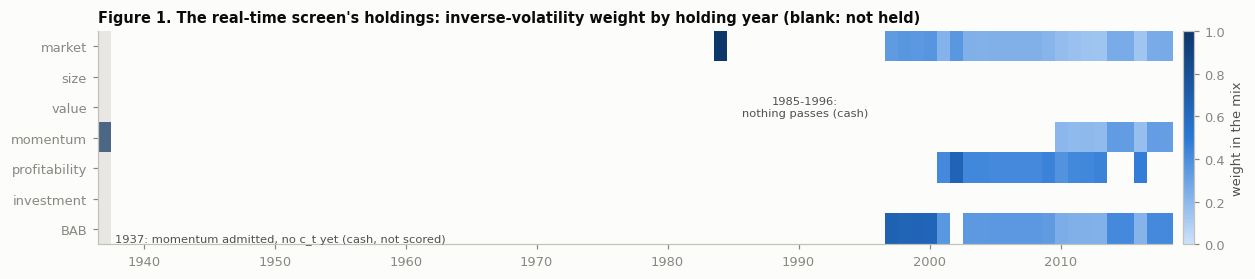

In [3]:
# What the walk-forward holds: the inverse-volatility weight of each factor in each holding year
w = RECIPES.xs("inv_vol", level="method").filter(regex="^w_")
w.columns = w.columns.str.removeprefix("w_")
w.index = w.index.year + 1                                         # set at the year-end, held the next year
years = np.arange(1937, 2019)
grid = w.reindex(years).fillna(0.0)[FACTORS].T
fig, ax = plt.subplots(figsize=(11.5, 2.6))
masked = np.ma.masked_equal(grid.to_numpy(), 0.0)
im = ax.imshow(masked, aspect="auto", cmap=SEQUENTIAL, vmin=0, vmax=1, interpolation="nearest",
               extent=(years[0] - 0.5, years[-1] + 0.5, len(FACTORS) - 0.5, -0.5))
ax.set_yticks(range(len(FACTORS)), ["market", "size", "value", "momentum", "profitability", "investment", "BAB"])
ax.grid(False)
ax.axvspan(1936.5, 1937.5, color=AXIS, alpha=0.35, lw=0)
ax.text(1937.8, 6.3, "1937: momentum admitted, no c_t yet (cash, not scored)", fontsize=7.5, color=INK2, va="center")
ax.text(1990.5, 2.0, "1985-1996:\nnothing passes (cash)", fontsize=7.5, color=INK2, ha="center", va="center")
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cb.set_label("weight in the mix", color=INK2)
ax.set_title("Figure 1. The real-time screen's holdings: inverse-volatility weight by holding year (blank: not held)")
fig.tight_layout()
held = w.reindex(years).dropna(how="all")
print("holding years:", len(held), "| years by number of factors held:", held.gt(0).sum(axis=1).value_counts().sort_index().to_dict())

In [4]:
tab = RECIPES.xs("inv_vol", level="method")[["assets", "dropped", "window_start"]].copy()
tab.index = [f"{d.date()} (held {d.year + 1})" for d in tab.index]
tab["window_start"] = pd.to_datetime(tab["window_start"]).dt.date
display(tab)

,assets,dropped,window_start
1936-12-31 (held 1937),mom,NaN,1927-01-03
1983-12-30 (held 1984),mkt,NaN,1973-12-31
1996-12-31 (held 1997),mkt bab,NaN,1987-01-02
1997-12-31 (held 1998),mkt bab,NaN,1988-01-04
1998-12-31 (held 1999),mkt bab,NaN,1989-01-03
1999-12-31 (held 2000),mkt bab,NaN,1990-01-02
2000-12-29 (held 2001),mkt rmw bab,NaN,1990-12-31
2001-12-31 (held 2002),mkt rmw,NaN,1992-01-02
2002-12-31 (held 2003),mkt rmw bab,NaN,1993-01-04
2003-12-31 (held 2004),mkt rmw bab,NaN,1994-01-03


**Reading.**

- **For most of history nothing passes.** Momentum's one-year pass in 1936 has no $c_t$ yet (it would need 120 months of forecasts), so 1937 is in cash. After that, nothing passes until the market at the end of 1983. Nothing passes again at the year-ends from 1984 to 1995: the market fails filter 6 (stability), because its α is negative in the second or third of the three equal eras of its history so far.
- **From 1997 the book is a mix:**
  - market and BAB throughout, except that BAB skips 2002;
  - profitability in 2001–2013 and again in 2016;
  - momentum from 2010, once its level φ crosses 0.5.
- **So the primary book scores 276 months:** 12 in 1984, when it holds the market alone, and 264 from 1997 to 2018. The weekly variants score the same months, plus a partial January 1985 that the family drops.
- **No duplicates are dropped** at any year-end.

## 3. The primary test

The screened book, inverse-volatility mix, M3 GJR-GARCH, inverse-variance timing, monthly, cap 1.5, before costs. **It is an upper bound**: paper BAB and profitability cannot be traded. M3 was chosen in Phase 6 by a 0.002 margin.

In [5]:
p = PRIMARY_ROW
test = pd.Series({"months scored": int(p["months"]), "first": p["first"], "last": p["last"],
                  "Sharpe: timed": p["sharpe"], "Sharpe: buy-and-hold": p["bh_sharpe"], "Sharpe gain": p["gain"],
                  "standard error": p["se"], "one-sided p": p["p"], "95% lower bound": p["lower"], "95% upper bound": p["upper"],
                  "minimum detectable effect (80% power)": p["mde"], "reading": p["reading"],
                  "volatility: timed": p["volatility"], "volatility: buy-and-hold": p["bh_volatility"], "mean size": p["mean_size"]})
display(test.to_frame("primary test"))

,primary test
months scored,276
first,1984-01
last,2018-12
Sharpe: timed,0.7460
Sharpe: buy-and-hold,0.7329
Sharpe gain,0.0131
standard error,0.1801
one-sided p,0.4710
95% lower bound,-0.2832
95% upper bound,0.3094


In [6]:
def side_by_side(r):
    """Timed run and buy-and-hold, one row per metric."""
    rows = [("Sharpe ratio", "sharpe", "bh_sharpe", "{:.3f}"), ("CER, γ = 5", "cer", "bh_cer", "{:.2%}"),
            ("Sortino ratio", "sortino", "bh_sortino", "{:.3f}"), ("maximum drawdown", "max_drawdown", "bh_max_drawdown", "{:.1%}"),
            ("volatility", "volatility", "bh_volatility", "{:.2%}"), ("mean excess return", "mean", "bh_mean", "{:.2%}"),
            ("turnover a year", "turnover_a_year", "bh_turnover_a_year", "{:.2f}")]
    out = pd.DataFrame({name: {"timed": f.format(r[a]), "buy-and-hold": f.format(r[b])} for name, a, b, f in rows}).T
    extra = {"mean size": f"{r['mean_size']:.2f}", "share of months capped": f"{r['share_capped']:.0%}",
             "turnover per rebalance": f"{r['turnover_per_rebalance']:.3f}", "break-even κ (one-way)": f"{r['break_even']:.2%}",
             "spanning α a year (t)": f"{r['alpha']:+.2%} ({r['t_alpha']:.2f})"}
    return pd.concat([out, pd.DataFrame({"timed": extra, "buy-and-hold": ""})])
display(side_by_side(PRIMARY_ROW))

,timed,buy-and-hold
Sharpe ratio,0.746,0.733
"CER, γ = 5",3.47%,4.12%
Sortino ratio,1.255,1.145
maximum drawdown,-18.9%,-33.5%
volatility,5.77%,7.59%
mean excess return,4.30%,5.56%
turnover a year,3.05,0.49
mean size,0.76,
share of months capped,10%,
turnover per rebalance,0.256,


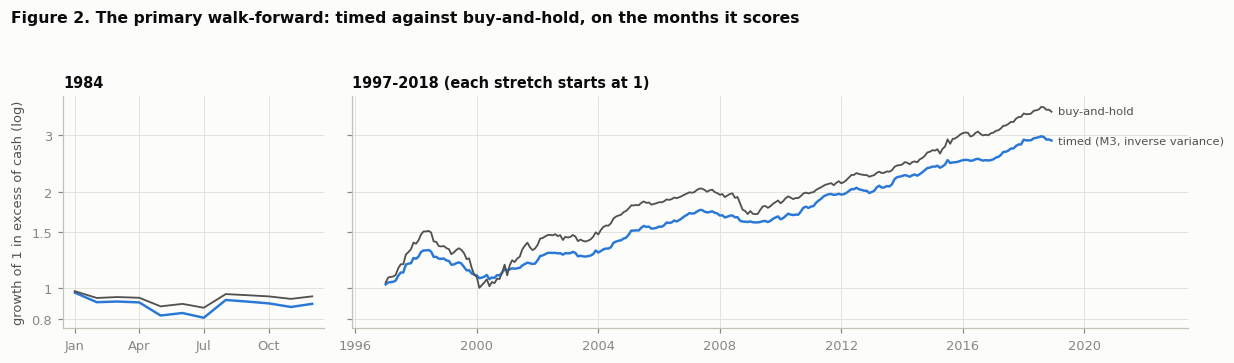

In [7]:
prim = RUNS.query("book == 'family' and model == 'M3' and rule == 'inv_var' and mix == 'inv_vol' and freq == 'monthly'").set_index("month")
t = pd.PeriodIndex(prim.index, freq="M").to_timestamp()
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.3), gridspec_kw={"width_ratios": [1, 3.2]}, sharey=True)
for ax, (lo, hi) in zip(axes, [("1984-01", "1984-12"), ("1997-01", "2018-12")]):
    seg = (t >= lo) & (t <= pd.Timestamp(hi) + pd.offsets.MonthEnd(0))
    for col, color, label in (("excess", BLUE, "timed (M3, inverse variance)"), ("bench_excess", INK2, "buy-and-hold")):
        wealth = (1 + prim.loc[seg, col]).cumprod()
        ax.plot(t[seg], wealth, color=color, lw=1.6 if col == "excess" else 1.2, label=label)
        if hi.startswith("2018"):
            ax.annotate(label, (t[seg][-1], wealth.iloc[-1]), xytext=(4, 0), textcoords="offset points",
                        fontsize=7.5, color=INK2, va="center")
    ax.set_yscale("log")
    ax.minorticks_off()
    ax.set_yticks([0.8, 1, 1.5, 2, 3], ["0.8", "1", "1.5", "2", "3"])
axes[0].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[0].set_title("1984")
axes[1].set_title("1997-2018 (each stretch starts at 1)")
axes[0].set_ylabel("growth of 1 in excess of cash (log)")
axes[1].set_xlim(right=pd.Timestamp("2023-06-01"))
fig.suptitle("Figure 2. The primary walk-forward: timed against buy-and-hold, on the months it scores", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92))

mean size 0.76; capped in 10% of months; c_t from 9.07e-05 to 1.49e-03


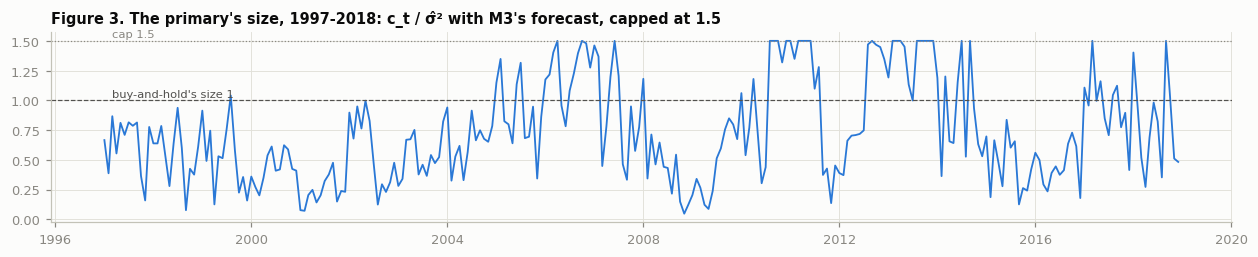

In [8]:
run = PRIMARY_RUN.copy()
run.index = pd.PeriodIndex(run.index, freq="M").to_timestamp()
late = run.loc["1997":]
fig, ax = plt.subplots(figsize=(11.5, 2.4))
ax.plot(late.index, late["size"], color=BLUE, lw=1.2)
ax.axhline(1.0, color=INK2, lw=0.8, ls="--")
ax.axhline(e.ENGINE_RULES["max_size"], color=MUTED, lw=0.8, ls=":")
ax.text(late.index[2], 1.53, "cap 1.5", fontsize=7.5, color=MUTED)
ax.text(late.index[2], 1.03, "buy-and-hold's size 1", fontsize=7.5, color=INK2)
ax.set_title("Figure 3. The primary's size, 1997-2018: c_t / σ̂² with M3's forecast, capped at 1.5")
fig.tight_layout()
print(f"mean size {run['size'].mean():.2f}; capped in {run['capped'].mean():.0%} of months; "
      f"c_t from {run['c'].min():.2e} to {run['c'].max():.2e}")

**Result: inconclusive.**

- **The gain is +0.013** (0.746 against 0.733), with a standard error of 0.18. That gives p = 0.47 and a one-sided 95% interval of −0.28 to +0.31.
- **The test lacks power.** Its minimum detectable effect is 0.45: with 276 months, it would see a gain only if timing added about 0.45 to the Sharpe ratio. Entry 6 expected 0.4.
- **Timed runs smaller and smoother:**
  - mean size 0.76, capped in 10% of months;
  - volatility 5.8% against 7.6%;
  - maximum drawdown −19% against −34%, and a Sortino ratio of 1.26 against 1.14.
- **It earns less.** The mean excess return is 4.3% against 5.6%, so the CER (γ = 5) is lower (Section 3b).
- **Break-even cost: 0.03%.** A gain this small vanishes at almost any trading cost.
- **Figure 2 shows where the gain went.**
  - In 1984 (left panel) the timed run, levered up to 1.5 after a calm 1983, lost more than buy-and-hold.
  - From 1997 (right panel) buy-and-hold ends higher, because it earns more (6.0% a year against 4.9%). The timed path is smoother: it falls less in 1998–2000 and 2008, and its Sharpe ratio is 1.15 against 0.84.
  - Section 9 shows that 1984 decides the test.

### 3b. The CER test, the combination test and the placebo

In [9]:
comb = pd.Series({"out-of-sample months": int(p["comb_months"]), "from": p["comb_first"],
                  "CER: buy-and-hold + timed + cash": p["comb_cer"], "CER: buy-and-hold + cash": p["comb_alone_cer"],
                  "CER gain of the three-way split": p["comb_gain"], "one-sided p (bootstrap)": p["comb_p"],
                  "mean weight on the timed run": p["comb_w_managed"], "mean weight on buy-and-hold (with timed)": p["comb_w_bench"],
                  "mean weight on buy-and-hold (alone)": p["comb_w_alone"]})
cer = pd.Series({"CER: timed": p["cer"], "CER: buy-and-hold": p["bh_cer"], "CER gain": p["cer_gain"], "one-sided p (bootstrap)": p["cer_p"]})
display(cer.to_frame("CER test"), comb.to_frame("combination test"))

,CER test
CER: timed,0.0347
CER: buy-and-hold,0.0412
CER gain,-0.0065
one-sided p (bootstrap),0.7217


,combination test
out-of-sample months,156
from,2006-01
CER: buy-and-hold + timed + cash,0.0729
CER: buy-and-hold + cash,0.0644
CER gain of the three-way split,0.0085
one-sided p (bootstrap),0.0916
mean weight on the timed run,0.8985
mean weight on buy-and-hold (with timed),0.8768
mean weight on buy-and-hold (alone),1.4414


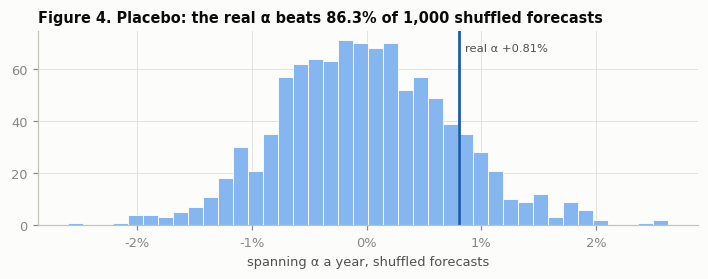

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 2.6))
ax.hist(PLACEBO, bins=40, color=LIGHT, edgecolor=SURFACE, linewidth=0.6)
a = SUMMARY["placebo_alpha"]
ax.axvline(a, color=DARK, lw=1.8)
ax.annotate(f"real α {a:+.2%}", (a, ax.get_ylim()[1] * 0.9), xytext=(4, 0), textcoords="offset points", fontsize=7.5, color=INK2)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("spanning α a year, shuffled forecasts")
ax.set_title(f"Figure 4. Placebo: the real α beats {SUMMARY['placebo_share']:.1%} of 1,000 shuffled forecasts")
fig.tight_layout()

**Reading.**

- **CER: timed loses 0.65 points a year** (3.47% against 4.12%), with p = 0.72. With the cap and a mean size of 0.76, the timed run carries less risk and earns less. At γ = 5 the lower risk is not worth the lower mean.
- **The combination test: +0.85 points, p = 0.09. It does not pass at 5%.**
  - The real-time investor holds about 0.9 of the timed run plus 0.9 of buy-and-hold, against 1.4 of buy-and-hold alone.
  - That beats buy-and-hold plus cash by 0.85 points of CER over 2006–2018 (156 months).
  - This is Cederburg et al.'s test, and it comes out positive but not significant. Its 156 months start after 1984, so 1984 cannot hurt it.
- **The placebo fails.** The real spanning α (+0.81%, t 1.1) beats 86.3% of 1,000 shuffled forecasts, short of the 95% bar. In Phase 6 the fixed book beat all 1,000.

In [11]:
cols = ["months", "first", "sharpe", "bh_sharpe", "gain", "se", "p", "reading", "cer", "bh_cer", "volatility", "bh_volatility", "mean_size"]
bridge = pd.DataFrame({"screened book (the primary)": PRIMARY_ROW[cols], "Phase 6's fixed book": TRACKS.loc["fixed", cols]}).T
display(bridge)

,months,first,sharpe,bh_sharpe,gain,se,p,reading,cer,bh_cer,volatility,bh_volatility,mean_size
screened book (the primary),276,1984-01,0.7460,0.7329,0.0131,0.1801,0.4710,inconclusive,0.0347,0.0412,0.0577,0.0759,0.7557
Phase 6's fixed book,817,1950-12,1.5665,1.2112,0.3553,0.1008,0.0002,edge,0.0868,0.0740,0.0614,0.0717,1.0170


**Against Phase 6.** The same rules on Phase 6's fixed book (market, momentum and BAB from 1950, the full-sample asset list) still read "edge": +0.36 over 817 months, p = 0.0002. The two books differ in which assets they hold, and in when they hold them. Section 9 separates the two: on the same 276 months the fixed book gains +0.61, so the years are not the problem.

## 4. The family of 192 variants

All on the 276 common months, the primary's. Raw p-values are Ledoit-Wolf; Romano-Wolf and Holm adjust them for 192 tries.

In [12]:
f = FAMILY
counts = pd.DataFrame({
    "raw p < 0.05": [int((f["p"] < 0.05).sum())], "Romano-Wolf adjusted p < 0.05": [int(f["edge_rw"].sum())],
    "Holm adjusted p < 0.05": [int(f["edge_holm"].sum())], "gain > 0": [int((f["gain"] > 0).sum())],
    "CER gain > 0": [int((f["cer_gain"] > 0).sum())], "CER test p < 0.05": [int((f["cer_p"] < 0.05).sum())],
    "combination gain > 0": [int((f["comb_gain"] > 0).sum())], "combination p < 0.05": [int((f["comb_p"] < 0.05).sum())]},
    index=["variants (of 192)"])
display(counts)
print(f"smallest raw p {f['p'].min():.2e} (Holm's first bar: 0.05/192 = {0.05/192:.5f})")

,raw p < 0.05,Romano-Wolf adjusted p < 0.05,Holm adjusted p < 0.05,gain > 0,CER gain > 0,CER test p < 0.05,combination gain > 0,combination p < 0.05
variants (of 192),1,0,0,185,55,0,181,36


smallest raw p 4.49e-02 (Holm's first bar: 0.05/192 = 0.00026)


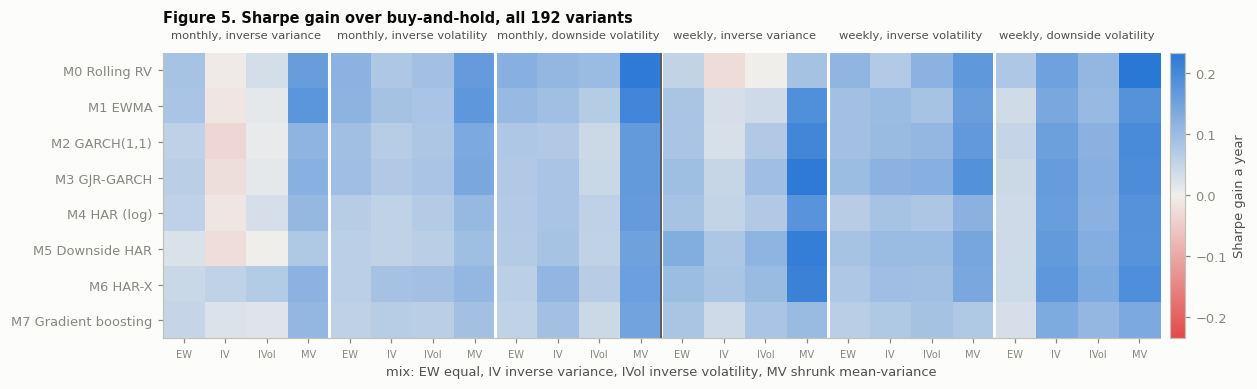

In [13]:
# Sharpe gain over buy-and-hold for every variant: rows are forecasts, columns the 24 cells
cells = [(r, x, q) for q in wf.FAMILY["freq"] for r in wf.FAMILY["rule"] for x in wf.FAMILY["mix"]]
G = pd.DataFrame({c: [FAMILY.loc[(m,) + c, "gain"] for m in md.ORDER] for c in cells}, index=md.ORDER)
E = pd.DataFrame({c: [FAMILY.loc[(m,) + c, "edge_rw"] for m in md.ORDER] for c in cells}, index=md.ORDER)
lim = np.abs(G.to_numpy()).max()
fig, ax = plt.subplots(figsize=(11.5, 3.6))
im = ax.imshow(G.to_numpy(), cmap=DIVERGING, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto", interpolation="nearest")
yy, xx = np.nonzero(E.to_numpy())
ax.scatter(xx, yy, s=14, color=INK, marker="o", label="beats buy-and-hold after Romano-Wolf")
ax.set_yticks(range(8), [f"{m} {md.NAMES[m]}" for m in md.ORDER])
short = {"equal": "EW", "inv_var": "IV", "inv_vol": "IVol", "shrunk_mv": "MV"}              # the four mixes
ax.set_xticks(range(24), [short[x] for r, x, q in cells], fontsize=6.5, rotation=0)
for k, (q, r) in enumerate([(q, r) for q in wf.FAMILY["freq"] for r in wf.FAMILY["rule"]]):
    ax.text(4 * k + 1.5, -0.9, f"{q}, {NAMES[r]}", ha="center", fontsize=7.5, color=INK2)
    if k:
        ax.axvline(4 * k - 0.5, color=SURFACE, lw=2)
ax.axvline(11.5, color=INK2, lw=1.2)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
cb.set_label("Sharpe gain a year", color=INK2)
ax.set_title("Figure 5. Sharpe gain over buy-and-hold, all 192 variants", pad=20)
ax.set_xlabel("mix: EW equal, IV inverse variance, IVol inverse volatility, MV shrunk mean-variance")
if len(xx):
    ax.legend(loc="lower right", bbox_to_anchor=(1.0, -0.32), fontsize=7.5)
fig.tight_layout()

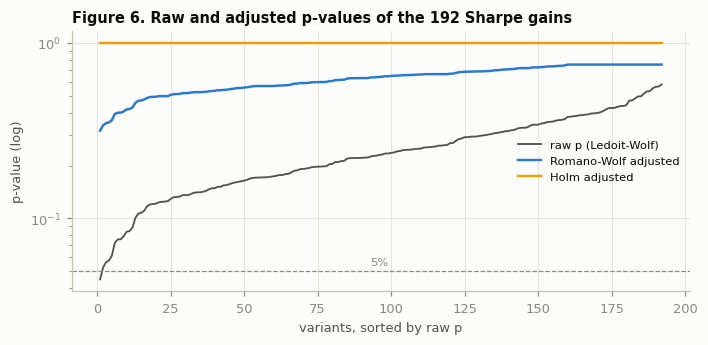

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
order = np.argsort(FAMILY["p"].to_numpy())
k = np.arange(1, len(FAMILY) + 1)
ax.plot(k, FAMILY["p"].to_numpy()[order], color=INK2, lw=1.2, label="raw p (Ledoit-Wolf)")
ax.plot(k, FAMILY["p_rw"].to_numpy()[order], color=BLUE, lw=1.6, label="Romano-Wolf adjusted")
ax.plot(k, FAMILY["p_holm"].to_numpy()[order], color=AMBER, lw=1.6, label="Holm adjusted")
ax.axhline(0.05, color=MUTED, lw=0.8, ls="--")
ax.text(len(FAMILY) * 0.5, 0.054, "5%", ha="center", fontsize=7.5, color=MUTED)
ax.set_yscale("log")
ax.set_xlabel("variants, sorted by raw p")
ax.set_ylabel("p-value (log)")
ax.legend(fontsize=7.5, loc="center right")
ax.set_title("Figure 6. Raw and adjusted p-values of the 192 Sharpe gains")
fig.tight_layout()

In [15]:
# How much each dimension moves the gain: the median gain of the 192 variants by level
rows = []
for dim in ["model", "rule", "mix", "freq"]:
    g = FAMILY.groupby(level=dim)["gain"]
    for level, s in g:
        rows.append({"dimension": dim, "level": NAMES.get(level, level), "median gain": s.median(), "min": s.min(), "max": s.max(),
                     "beat buy-and-hold after Romano-Wolf": int(FAMILY.xs(level, level=dim)["edge_rw"].sum()), "variants": len(s)})
display(pd.DataFrame(rows).set_index(["dimension", "level"]))

median gain     min    max  beat buy-and-hold after Romano-Wolf  variants
dimension level                                                                                          
model     M0                         0.1041 -0.0268 0.2341                                    0        24
          M1                         0.0911 -0.0138 0.2064                                    0        24
          M2                         0.0874 -0.0339 0.2033                                    0        24
          M3                         0.0951 -0.0227 0.2280                                    0        24
          M4                         0.0763 -0.0119 0.1811                                    0        24
          M5                         0.0857 -0.0250 0.2212                                    0        24
          M6                         0.0931  0.0418 0.2135                                    0        24
          M7                         0.0766  0.0216 0.1469                                    0        24
rule      downside volatility        0.1087  0.0304 0.2341                                    0        64
          inverse variance           0.0734 -0.0339 0.2280                                    0        64
          inverse volatility         0.0906  0.0551 0.1840                                    0        64
mix       equal                      0.0736  0.0261 0.1289                                    0        48
          inverse variance           0.0806 -0.0339 0.1717                                    0        48
          inverse volatility         0.0814  0.0015 0.1337                                    0        48
          shrunk mean-variance       0.1619  0.0756 0.2341                                    0        48
freq      monthly                    0.0763 -0.0339 0.2268                                    0        96
          weekly                     0.0998 -0.0268 0.2341                                    0        96

In [16]:
cols = ["sharpe", "bh_sharpe", "gain", "se", "p", "p_rw", "p_holm", "cer_gain", "cer_p", "comb_gain", "comb_p",
        "volatility", "mean_size", "turnover_a_year", "break_even"]
top = FAMILY.sort_values("gain", ascending=False)[cols].head(10)
display(top.style.format({"sharpe": "{:.3f}", "bh_sharpe": "{:.3f}", "gain": "{:+.3f}", "se": "{:.3f}", "p": "{:.4f}",
                          "p_rw": "{:.3f}", "p_holm": "{:.3f}", "cer_gain": "{:+.2%}", "cer_p": "{:.3f}", "comb_gain": "{:+.2%}",
                          "comb_p": "{:.3f}", "volatility": "{:.2%}", "mean_size": "{:.2f}", "turnover_a_year": "{:.2f}",
                          "break_even": "{:.2%}"}))

In [17]:
dsr = pd.Series({"best variant (largest Sharpe gain)": SUMMARY["best_variant"],
                 "its Sharpe ratio, a month": float(SUMMARY["dsr_sharpe_monthly"]),
                 "its buy-and-hold's, a month": float(SUMMARY["dsr_bh_sharpe_monthly"]),
                 "E[max of 192 normals]": float(SUMMARY["dsr_expected_max"]),
                 "threshold, a month": float(SUMMARY["dsr_threshold_monthly"]),
                 "skewness": float(SUMMARY["dsr_skew"]), "kurtosis": float(SUMMARY["dsr_kurtosis"]),
                 "months": int(float(SUMMARY["dsr_months"])), "deflated Sharpe ratio": float(SUMMARY["dsr_dsr"])})
display(dsr.to_frame("deflated Sharpe ratio"))

,deflated Sharpe ratio
best variant (largest Sharpe gain),M0 | down_vol | shrunk_mv | weekly
"its Sharpe ratio, a month",0.2831
"its buy-and-hold's, a month",0.2155
E[max of 192 normals],2.7522
"threshold, a month",0.2578
skewness,0.4315
kurtosis,5.4010
months,276
deflated Sharpe ratio,0.6651


**Result: no variant beats buy-and-hold after adjustment.**

- **The gains lean positive but are small.** 185 of 192 are above zero, with a median of +0.09 and a maximum of +0.23. The standard errors run from 0.07 to 0.20, so no single gain is far from zero.
- **One raw p-value is below 5%**: M3, inverse-volatility timing, shrunk mean-variance mix, weekly (+0.18, p = 0.045). With 192 tries, about 10 such p-values would be expected by luck if nothing worked, so one is fewer than chance.
  - After adjustment its p is 0.32 (Romano-Wolf) and 1.0 (Holm).
  - The smallest raw p would have had to be below 0.00026 to pass Holm's first step.
- **The best variant fails the deflated Sharpe ratio.** It is M0, downside volatility, shrunk mean-variance, weekly (+0.23).
  - Its Sharpe ratio is 0.283 a month, against its buy-and-hold's 0.215.
  - The best of 192 useless tries would reach a threshold of 0.258 by luck, so it clears that only narrowly: DSR 0.67, against the 0.95 bar.
- **Where the gains sit.** The mix matters most:
  - shrunk mean-variance gains about twice as much as the others (median +0.16 against +0.07–0.08);
  - weekly beats monthly (+0.10 against +0.08);
  - downside volatility beats inverse volatility, which beats inverse variance (+0.11, +0.09, +0.07);
  - the forecast matters least (medians +0.08 to +0.10).
  - These are patterns in point estimates that do not pass, not findings.
- **Drawdown and the CER.** All 192 cut the maximum drawdown, and 190 raise the Sortino ratio. Yet no CER gain is significant (55 of 192 are positive), because the timed runs carry less risk (5.1% volatility against 7.4%, median) and earn less.
- **The combination test.** 181 of 192 gains are positive, and 36 have a raw p below 5%. These p-values are not adjusted; Holm's smallest adjusted p is 0.64.

## 5. Q3: does a better forecast beat the baseline?

In each of the 24 cells (rule × mix × frequency), each model's Sharpe ratio minus rolling RV's (M0) in the same cell. Ledoit-Wolf one-sided p-values, then Romano-Wolf over the 168 comparisons.

In [18]:
rows = {}
for m in md.ORDER[1:]:
    q = VS_M0.xs(m, level="model")
    rows[f"{m} {md.NAMES[m]}"] = {"median Sharpe gain over M0": q["diff"].median(), "cells where it beats M0 (of 24)": int((q["diff"] > 0).sum()),
                                  "raw p < 0.05": int((q["p"] < 0.05).sum()), "beats M0 after Romano-Wolf (of 24)": int(q["beats_m0_rw"].sum()),
                                  "its variants beating buy-and-hold after Romano-Wolf": int(FAMILY.xs(m, level="model")["edge_rw"].sum())}
rows["M0 Rolling RV (the baseline)"] = {"its variants beating buy-and-hold after Romano-Wolf": int(FAMILY.xs("M0", level="model")["edge_rw"].sum())}
display(pd.DataFrame(rows).T)

,median Sharpe gain over M0,cells where it beats M0 (of 24),raw p < 0.05,beats M0 after Romano-Wolf (of 24),its variants beating buy-and-hold after Romano-Wolf
M1 EWMA,-0.0068,8.0000,0.0000,0.0000,0.0000
"M2 GARCH(1,1)",-0.0232,7.0000,0.0000,0.0000,0.0000
M3 GJR-GARCH,-0.0154,9.0000,0.0000,0.0000,0.0000
M4 HAR (log),-0.0261,7.0000,0.0000,0.0000,0.0000
M5 Downside HAR,-0.0273,7.0000,0.0000,0.0000,0.0000
M6 HAR-X,-0.0125,11.0000,0.0000,0.0000,0.0000
M7 Gradient boosting,-0.0296,6.0000,0.0000,0.0000,0.0000
M0 Rolling RV (the baseline),NaN,NaN,NaN,NaN,0.0000


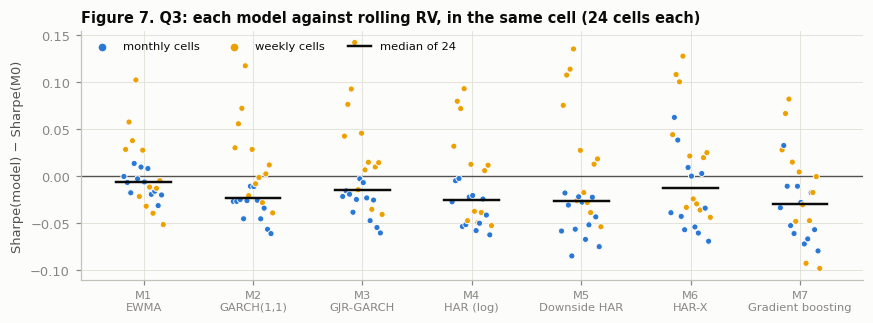

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.0))
for i, m in enumerate(md.ORDER[1:]):
    q = VS_M0.xs(m, level="model")
    weekly_ = q.index.get_level_values("freq") == "weekly"
    jitter = np.linspace(-0.18, 0.18, len(q))
    ax.scatter(np.full(len(q), i) + jitter, q["diff"], s=16, color=np.where(weekly_, AMBER, BLUE), edgecolor=SURFACE, linewidth=0.6, zorder=3)
    ax.plot([i - 0.25, i + 0.25], [q["diff"].median()] * 2, color=INK, lw=1.6, zorder=4)
ax.axhline(0, color=INK2, lw=0.9)
ax.set_xticks(range(7), [f"{m}\n{md.NAMES[m]}" for m in md.ORDER[1:]], fontsize=7.5)
ax.set_ylabel("Sharpe(model) − Sharpe(M0)")
ax.scatter([], [], s=16, color=BLUE, label="monthly cells")
ax.scatter([], [], s=16, color=AMBER, label="weekly cells")
ax.plot([], [], color=INK, lw=1.6, label="median of 24")
ax.legend(fontsize=7.5, loc="upper left", ncol=3)
ax.set_title("Figure 7. Q3: each model against rolling RV, in the same cell (24 cells each)")
fig.tight_layout()

**Result: no.**

- **Not one of the 168 comparisons has a raw p below 5%,** let alone after Romano-Wolf.
- **Every model's median gain over M0 is slightly negative,** from −0.007 (EWMA) to −0.030 (boosting). Each model beats M0 in 6–11 of its 24 cells.
- **No model's variants beat buy-and-hold after adjustment,** M0's included, so the comparison of counts is 0 against 0.
- **As in Phase 6, the forecasts differ by little:** within a cell the eight Sharpe ratios spread by 0.03–0.14 (median 0.06), less than one standard error of a gain. Rolling RV, the papers' baseline, is as good a timing signal here as anything more elaborate.

## 6. Q4: does forecast accuracy explain strategy value?

Scorecard A (Phase 6's QLIKE and 90% Model Confidence Set), on the primary cell of the screened book.

In [20]:
display(Q4.style.format({"qlike": "{:.4f}", "qlike_median": "{:.4f}", "rv_over_forecast": "{:.3f}", "mcs_p": "{:.3f}",
                         "primary_cell_sharpe": "{:.3f}", "median_gain_over_m0": "{:+.3f}"}))
print(f"rank correlation, QLIKE vs the primary cell's Sharpe: {float(SUMMARY['q4_rank_corr_primary_cell']):+.2f}; "
      f"QLIKE vs median gain over M0 (M1-M7): {float(SUMMARY['q4_rank_corr_median_gain']):+.2f}")

,qlike,qlike_median,rv_over_forecast,mcs_p,in_mcs,qlike_rank,months,primary_cell_sharpe,median_gain_over_m0,cells_beating_m0,variants_with_edge_rw
M0,0.2760,0.0805,1.008,0.003,False,8,275,0.766,+0.000,nan,0
M1,0.2380,0.0670,1.018,0.188,True,7,275,0.748,-0.007,8.000000,0
M2,0.2213,0.0626,0.992,0.672,True,5,275,0.740,-0.023,7.000000,0
M3,0.2201,0.0661,0.981,0.672,True,4,275,0.746,-0.015,9.000000,0
M4,0.2200,0.0662,1.075,0.672,True,3,275,0.763,-0.026,7.000000,0
M5,0.2140,0.0718,1.083,0.672,True,2,275,0.734,-0.027,7.000000,0
M6,0.2015,0.0817,1.011,1.000,True,1,275,0.804,-0.012,11.000000,0
M7,0.2312,0.0705,1.049,0.672,True,6,275,0.755,-0.030,6.000000,0


rank correlation, QLIKE vs the primary cell's Sharpe: -0.05; QLIKE vs median gain over M0 (M1-M7): -0.07


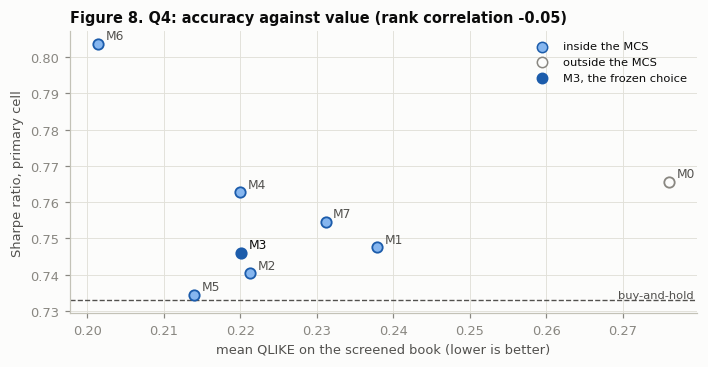

In [21]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for m in md.ORDER:
    x, y, inside = Q4.loc[m, "qlike"], Q4.loc[m, "primary_cell_sharpe"], bool(Q4.loc[m, "in_mcs"])
    ax.scatter(x, y, s=46, color=DARK if m == "M3" else (LIGHT if inside else SURFACE), edgecolor=DARK if inside or m == "M3" else MUTED,
               linewidth=1.2, zorder=3)
    ax.annotate(m, (x, y), xytext=(5, 3), textcoords="offset points", fontsize=8, color=INK if m == "M3" else INK2)
ax.axhline(PRIMARY_ROW["bh_sharpe"], color=INK2, lw=0.9, ls="--")
ax.text(ax.get_xlim()[1], PRIMARY_ROW["bh_sharpe"], "buy-and-hold ", ha="right", va="bottom", fontsize=7.5, color=INK2)
ax.set_xlabel("mean QLIKE on the screened book (lower is better)")
ax.set_ylabel("Sharpe ratio, primary cell")
handles = [plt.scatter([], [], s=46, color=LIGHT, edgecolor=DARK, label="inside the MCS"),
           plt.scatter([], [], s=46, color=SURFACE, edgecolor=MUTED, label="outside the MCS"),
           plt.scatter([], [], s=46, color=DARK, edgecolor=DARK, label="M3, the frozen choice")]
ax.legend(handles=handles, fontsize=7.5, loc="best")
ax.set_title(f"Figure 8. Q4: accuracy against value (rank correlation {float(SUMMARY['q4_rank_corr_primary_cell']):+.2f})")
fig.tight_layout()

**Result: accuracy does not explain value.**

- **The accuracy ranking holds from Phase 6.**
  - HAR-X (M6) is the most accurate (QLIKE 0.202).
  - Rolling RV (M0) is the least (0.276), and the only model outside the MCS (p 0.003).
  - The other seven are statistically tied.
- **Value does not follow it.** The rank correlation between QLIKE and the primary cell's Sharpe ratio is −0.05. Against each model's median gain over M0 it is −0.07.
  - The most accurate model, HAR-X, does have the best primary-cell Sharpe ratio (0.80).
  - But the least accurate, rolling RV, is second (0.77), ahead of M3, the frozen choice (0.75).
- **As in Phase 6: forecast accuracy is not the bottleneck.** On this book, Phase 6's link between smooth forecasts and larger size does not carry the Sharpe ratio either.

## 7. The other books

None of these changes a choice (Entry 6, Section 8):
- **The ETF track** is the frozen choices on what can be traded, after costs: SPY alone with M2, and SPY plus MTUM's hedged tilt with M3. Each first forecasts at its 12th month and needs 36 pairs for $c_t$.
- **Two long-history references**, both already scored in Phase 6: the market factor at SPY's costs (M2), and Phase 6's fixed book (M3).

In [22]:
cols = ["label", "months", "first", "last", "sharpe", "bh_sharpe", "gain", "se", "p", "reading", "mde", "cer", "bh_cer", "cer_p",
        "comb_gain", "comb_p", "volatility", "bh_volatility", "max_drawdown", "bh_max_drawdown", "mean_size", "turnover_a_year", "break_even"]
display(TRACKS[cols].style.format({"sharpe": "{:.3f}", "bh_sharpe": "{:.3f}", "gain": "{:+.3f}", "se": "{:.3f}", "p": "{:.3f}",
                                   "mde": "{:.3f}", "cer": "{:.2%}", "bh_cer": "{:.2%}", "cer_p": "{:.3f}", "comb_gain": "{:+.2%}",
                                   "comb_p": "{:.3f}", "volatility": "{:.2%}", "bh_volatility": "{:.2%}", "max_drawdown": "{:.1%}",
                                   "bh_max_drawdown": "{:.1%}", "mean_size": "{:.2f}", "turnover_a_year": "{:.2f}",
                                   "break_even": "{:.2%}"}, na_rep="–"))

,label,months,first,last,sharpe,bh_sharpe,gain,se,p,reading,mde,cer,bh_cer,cer_p,comb_gain,comb_p,volatility,bh_volatility,max_drawdown,bh_max_drawdown,mean_size,turnover_a_year,break_even
book,,,,,,,,,,,,,,,,,,,,,,,
spy,"ETF track: SPY alone, M2",263,1997-02,2018-12,0.582,0.417,+0.165,0.147,0.130,inconclusive,0.365,3.35%,0.66%,0.134,+1.76%,0.239,10.35%,14.90%,-31.0%,-56.0%,0.89,2.62,0.70%
etf,"ETF track: SPY + MTUM tilt, M3",20,2017-05,2018-12,1.006,0.918,+0.088,0.170,0.303,inconclusive,0.423,5.57%,4.78%,0.279,–,–,6.63%,6.29%,-5.7%,-6.1%,0.93,2.80,0.29%
market,"Market factor at SPY's costs, M2 (Phase 6's SPY reference)",870,1946-07,2018-12,0.527,0.497,+0.030,0.065,0.322,inconclusive,0.161,2.45%,1.91%,0.282,-0.14%,0.626,14.16%,14.69%,-46.9%,-55.6%,1.07,3.02,0.19%
fixed,"Phase 6's fixed book (market + momentum + BAB), M3",817,1950-12,2018-12,1.567,1.211,+0.355,0.101,0.000,edge,0.251,8.68%,7.40%,0.013,+9.13%,0.026,6.14%,7.17%,-14.3%,-31.7%,1.02,3.56,0.64%


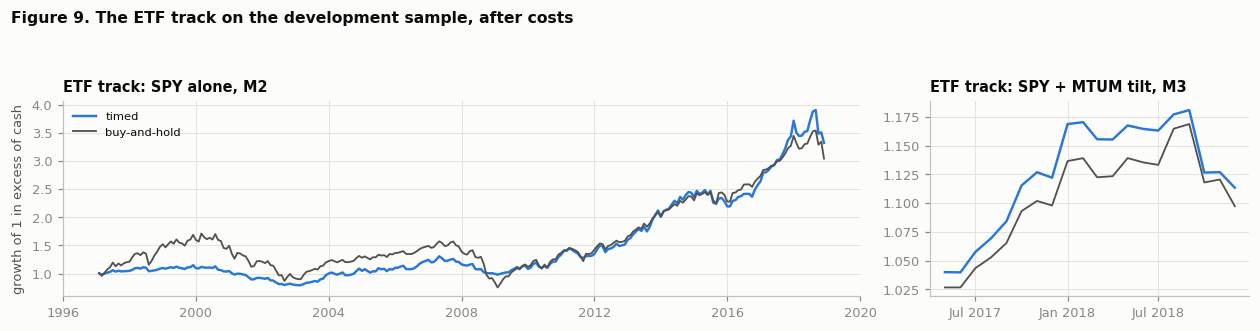

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.0), gridspec_kw={"width_ratios": [3, 1.2]})
for ax, name in zip(axes, ["spy", "etf"]):
    s = RUNS.query("book == @name").set_index("month")
    t = pd.PeriodIndex(s.index, freq="M").to_timestamp()
    for col, color, label in (("excess", BLUE, "timed"), ("bench_excess", INK2, "buy-and-hold")):
        wealth = (1 + s[col]).cumprod()
        ax.plot(t, wealth, color=color, lw=1.6 if col == "excess" else 1.2, label=label)
    ax.set_title(TRACKS.loc[name, "label"])
axes[1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[0].legend(fontsize=7.5, loc="upper left")
axes[0].set_ylabel("growth of 1 in excess of cash")
fig.suptitle("Figure 9. The ETF track on the development sample, after costs", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.9))

**Reading.**

- **SPY timed alone (February 1997 to December 2018, after costs): +0.17, inconclusive.**
  - 0.58 against 0.42, p = 0.13, minimum detectable effect 0.37.
  - Volatility falls from 14.9% to 10.4%, and the break-even cost is 0.70% one-way, well above SPY's 0.05%.
  - The CER gain (+2.7 points) and the combination gain (+1.8) are positive but not significant.
  - Timed lags buy-and-hold through the late-1990s rally, falls less in 2000–2002 and much less in 2008, and ends ahead (Figure 9).
- **SPY + MTUM tilt (May 2017 to December 2018): 20 months.** +0.09, which says nothing. Its first forecast needs 12 months of MTUM and its $c_t$ 36 more, so the holdout is its whole test.
- **The market factor at SPY's costs (1946–2018):** +0.03, inconclusive, as in Phase 6. The combination test loses (−0.14 points).
- **Phase 6's fixed book:** +0.36, edge (Section 3).

## 8. The results table

The primary test first (it stands alone, on its own months), then every variant on the common months, sorted by Sharpe gain. The full table, with every column, is `reports/phase7_results.csv`.

In [24]:
cols = ["row", "model", "rule", "mix", "freq", "months", "sharpe", "bh_sharpe", "gain", "p", "p_rw", "p_holm", "reading",
        "cer", "bh_cer", "cer_gain", "cer_p", "comb_gain", "comb_p", "sortino", "bh_sortino", "max_drawdown", "bh_max_drawdown",
        "volatility", "bh_volatility", "turnover_a_year", "break_even"]
order = pd.concat([RESULTS.iloc[:1], RESULTS.iloc[1:].sort_values("gain", ascending=False)])
display(order[cols].reset_index(drop=True).style.format(
    {"sharpe": "{:.3f}", "bh_sharpe": "{:.3f}", "gain": "{:+.3f}", "p": "{:.4f}", "p_rw": "{:.3f}", "p_holm": "{:.3f}",
     "cer": "{:.2%}", "bh_cer": "{:.2%}", "cer_gain": "{:+.2%}", "cer_p": "{:.3f}", "comb_gain": "{:+.2%}", "comb_p": "{:.3f}",
     "sortino": "{:.2f}", "bh_sortino": "{:.2f}", "max_drawdown": "{:.1%}", "bh_max_drawdown": "{:.1%}", "volatility": "{:.2%}",
     "bh_volatility": "{:.2%}", "turnover_a_year": "{:.2f}", "break_even": "{:.2%}"}, na_rep="–"))

,row,model,rule,mix,freq,months,sharpe,bh_sharpe,gain,p,p_rw,p_holm,reading,cer,bh_cer,cer_gain,cer_p,comb_gain,comb_p,sortino,bh_sortino,max_drawdown,bh_max_drawdown,volatility,bh_volatility,turnover_a_year,break_even
0,"primary test (stands alone, its own months)",M3,inv_var,inv_vol,monthly,276,0.746,0.733,+0.013,0.4710,–,–,inconclusive,3.47%,4.12%,-0.65%,0.722,+0.85%,0.092,1.26,1.14,-18.9%,-33.5%,5.77%,7.59%,3.05,0.03%
1,"variant (family, common months)",M0,down_vol,shrunk_mv,weekly,276,0.981,0.747,+0.234,0.0885,0.429,1.000,inconclusive,3.46%,4.14%,-0.68%,0.659,+0.90%,0.374,1.83,1.10,-10.9%,-30.2%,3.92%,7.37%,12.29,0.08%
2,"variant (family, common months)",M3,inv_var,shrunk_mv,weekly,276,0.975,0.747,+0.228,0.1173,0.486,1.000,inconclusive,4.43%,4.14%,+0.29%,0.398,+4.39%,0.057,1.71,1.10,-15.1%,-30.2%,5.26%,7.37%,8.69,0.15%
3,"variant (family, common months)",M0,down_vol,shrunk_mv,monthly,276,0.957,0.730,+0.227,0.1007,0.456,1.000,inconclusive,3.87%,4.08%,-0.21%,0.537,+3.05%,0.166,1.78,1.08,-11.4%,-31.1%,4.60%,7.52%,3.20,0.37%
4,"variant (family, common months)",M5,inv_var,shrunk_mv,weekly,276,0.968,0.747,+0.221,0.0759,0.401,1.000,inconclusive,4.15%,4.14%,+0.01%,0.483,+3.16%,0.137,1.75,1.10,-16.8%,-30.2%,4.91%,7.37%,8.38,0.14%
5,"variant (family, common months)",M6,inv_var,shrunk_mv,weekly,276,0.960,0.747,+0.214,0.0838,0.418,1.000,inconclusive,4.08%,4.14%,-0.07%,0.502,+3.68%,0.081,1.62,1.10,-15.5%,-30.2%,4.86%,7.37%,7.01,0.16%
6,"variant (family, common months)",M1,down_vol,shrunk_mv,monthly,276,0.937,0.730,+0.206,0.1408,0.524,1.000,inconclusive,3.72%,4.08%,-0.36%,0.577,+3.02%,0.179,1.67,1.08,-12.1%,-31.1%,4.51%,7.52%,2.93,0.37%
7,"variant (family, common months)",M2,inv_var,shrunk_mv,weekly,276,0.950,0.747,+0.203,0.1356,0.518,1.000,inconclusive,4.28%,4.14%,+0.14%,0.441,+4.30%,0.046,1.57,1.10,-16.1%,-30.2%,5.22%,7.37%,8.59,0.13%
8,"variant (family, common months)",M2,down_vol,shrunk_mv,weekly,276,0.941,0.747,+0.195,0.1603,0.551,1.000,inconclusive,3.92%,4.14%,-0.22%,0.540,+2.49%,0.220,1.72,1.10,-13.1%,-30.2%,4.77%,7.37%,6.97,0.15%
9,"variant (family, common months)",M3,down_vol,shrunk_mv,weekly,276,0.940,0.747,+0.193,0.1686,0.563,1.000,inconclusive,3.87%,4.14%,-0.27%,0.553,+2.46%,0.229,1.78,1.10,-12.7%,-30.2%,4.71%,7.37%,7.16,0.14%


In [25]:
# The tables come from the build. One live check: the primary rebuilt through the API matches them.
rec = screened.recipes(panel, screened.survivors(SCREEN))           # rebuilt from the screen table
book = screened.book(panel, rec, "inv_vol")
periods = execution.holding_periods(book)
res = runs.run(runs.prepare(book, md.forecasters(panel, False)["M3"]), 1.0, periods)
live = runs.metrics(res, periods)
print(f"Sharpe gain rebuilt: {live['gain']:+.10f}; in the table: {PRIMARY_ROW['gain']:+.10f}")
assert np.isclose(live["gain"], PRIMARY_ROW["gain"], rtol=0, atol=1e-12)

Sharpe gain rebuilt: +0.0130925984; in the table: +0.0130925984


## 9. What 1984 does (information, added after the run)

**Why this section exists.** The primary's gain over 1997–2018 looked large in Figure 2, yet the test over all 276 months reads +0.01. This section was added after the run to find out why. **It changes no reading:** the pre-registered results above stand.

**The mechanism.** A Sharpe ratio pools all months, so a month's weight is its variance. In 1984 the screen held the market alone:
- Buy-and-hold ran at 14% volatility and the timed run at 19% (size 0.73–1.5 after a calm 1983).
- From 1997 the book was a diversified mix: buy-and-hold's volatility was 2–9% in most years, and 14% in 2000–2001.
- So the 12 market-only months carry about as much variance as the 264 that follow. In them the timed run lost 9.4% a year against buy-and-hold's 4.8%.

In [26]:
# Information only, added after the run: the same tests without the 12 market-only months of 1984.
fam = RUNS.query("book == 'family'").copy()
fam["month"] = pd.PeriodIndex(fam["month"], freq="M")
fixed = RUNS.query("book == 'fixed'").set_index("month")
fixed.index = pd.PeriodIndex(fixed.index, freq="M")
variants = list(FAMILY.index)
X = {v: g.set_index("month") for v, g in fam.groupby(["model", "rule", "mix", "freq"])}

def gains(months):
    """Sharpe gain, standard error and raw p of every variant on these months, and Romano-Wolf and Holm."""
    t = [ev.sharpe_gain_test(X[v].loc[months].assign(size=np.nan)) for v in variants]
    g, se, p = (np.array([x[k] for x in t]) for k in ("gain", "se", "p"))
    xt = np.column_stack([X[v].loc[months, "excess"] for v in variants])
    xb = np.column_stack([X[v].loc[months, "bench_excess"] for v in variants])
    rw = np.max([stats.romano_wolf(g / se, (stats.sharpe_draws(C, xt) - stats.sharpe_draws(C, xb) - g) / se)
                 for C in (stats.counts(len(months), b) for b in stats.BOOT["blocks"])], axis=0)
    return pd.DataFrame({"gain": g, "se": se, "p": p, "p_rw": rw, "p_holm": stats.holm(p)}, index=FAMILY.index)

every = pd.PeriodIndex(X[wf.PRIMARY].index)
cuts = {"all 276 months (the pre-registered test)": every.intersection(pd.period_range("1984-01", "2018-12", freq="M")),
        "1997-2018 only (264 months)": pd.period_range("1997-01", "2018-12", freq="M")}
rows = {}
for name, months in cuts.items():
    g = gains(months)
    prim = X[wf.PRIMARY].loc[months]
    f = fixed.loc[months]
    rows[name] = {"primary: Sharpe gain": g.loc[wf.PRIMARY, "gain"], "primary: one-sided p": g.loc[wf.PRIMARY, "p"],
                  "primary: timed volatility": prim["excess"].std() * np.sqrt(12),
                  "Phase 6's fixed book, same months: gain": ev.sharpe(f["excess"]) - ev.sharpe(f["bench_excess"]),
                  "variants with raw p < 0.05": int((g["p"] < 0.05).sum()), "after Romano-Wolf": int((g["p_rw"] < 0.05).sum()),
                  "after Holm": int((g["p_holm"] < 0.05).sum()), "median gain of the 192": g["gain"].median()}
display(pd.DataFrame(rows).T.style.format({c: "{:+.3f}" for c in ["primary: Sharpe gain", "Phase 6's fixed book, same months: gain", "median gain of the 192"]}
                                          | {"primary: one-sided p": "{:.4f}", "primary: timed volatility": "{:.2%}"}))

,primary: Sharpe gain,primary: one-sided p,primary: timed volatility,"Phase 6's fixed book, same months: gain",variants with raw p < 0.05,after Romano-Wolf,after Holm,median gain of the 192
all 276 months (the pre-registered test),+0.013,0.4710,5.77%,+0.610,1.000000,0.000000,0.000000,+0.086
1997-2018 only (264 months),+0.304,0.0118,4.30%,+0.592,165.000000,65.000000,2.000000,+0.254


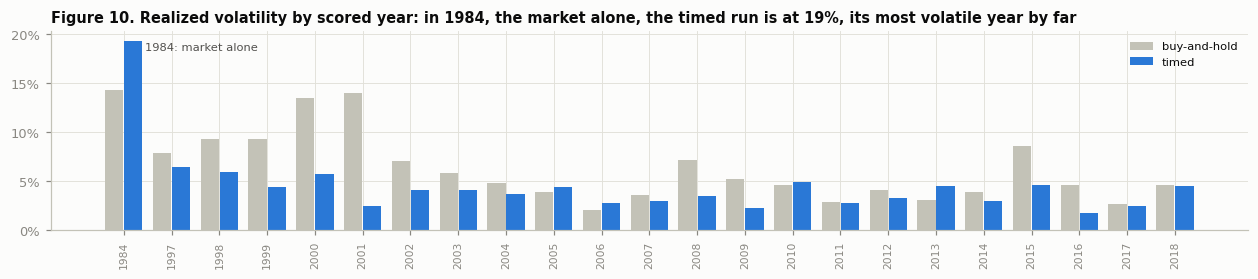

In [27]:
prim = X[wf.PRIMARY]
by_year = prim.groupby(prim.index.year).agg(timed=("excess", lambda s: s.std() * np.sqrt(12)), bh=("bench_excess", lambda s: s.std() * np.sqrt(12)))
fig, ax = plt.subplots(figsize=(11.5, 2.6))
x = np.arange(len(by_year))
ax.bar(x - 0.2, by_year["bh"], width=0.38, color=AXIS, label="buy-and-hold")
ax.bar(x + 0.2, by_year["timed"], width=0.38, color=BLUE, label="timed")
ax.set_xticks(x, by_year.index, fontsize=7, rotation=90)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(fontsize=7.5, loc="upper right")
ax.annotate("1984: market alone", (0, by_year["timed"].iloc[0]), xytext=(14, -6), textcoords="offset points", fontsize=7.5, color=INK2)
ax.set_title("Figure 10. Realized volatility by scored year: in 1984, the market alone, the timed run is at 19%, its most volatile year by far")
fig.tight_layout()

**Reading.**

- **Without 1984, the answer reverses:**
  - the primary's gain becomes +0.30, p = 0.012, which Entry 3 would read as "edge";
  - 165 of 192 variants have a raw p below 5%, 65 survive Romano-Wolf, and 2 survive Holm.
- **With 1984, nothing survives.** So Phase 7's verdict rests on one year of a different book.
- **Phase 6's fixed book gains +0.61 on the same 276 months.** It held the diversified mix in 1984 too, so a single-asset year did not swamp it.
- **This cut was chosen after seeing the result.** Read it as a diagnosis, not as evidence: picking the months that make a test pass is exactly what pre-registration rules out.

**Decisions for you before the holdout.** The holdout runs one book from 2019, as long as the screen keeps admitting market, momentum and BAB. But a year-end screen in the holdout could again leave a one-asset book, and that year would dominate the test the same way. Options, to be fixed in a dated entry before Phase 9:

1. **Keep the rule as is.** The holdout test pools every scored month, whatever the book holds.
2. **Score only diversified years.** A year whose screen admits fewer than two assets is treated like an empty one (cash, not scored). This is a new rule written after this result, so it would have to be labelled that way. On the development sample it would remove 1984.
3. **Score each holding year at equal weight**, for example by scaling each year's returns by buy-and-hold's volatility over the past 10 years, known at the year-end. This is also new, and it changes the statistic.

Whatever you choose, Phase 7's development-sample result stays as run: inconclusive, with the 1997–2018 cut beside it as information.

## Using the walk-forward

```python
from src.data.load import load_dev, load_etf_ohlc_dev
from src import models as md
from src.engine import execution
from src.walkforward import runs, screened

panel, ohlc = load_dev(), load_etf_ohlc_dev()
table = screened.screen_all(panel, ohlc, jobs=-2)              # Phase 3's screen at every year-end
rec = screened.recipes(panel, screened.survivors(table))       # duplicates, then the four mixes, at each year-end
book = screened.book(panel, rec, "inv_vol", freq="M")          # positions per holding month ("W-FRI" for weeks)
periods = execution.holding_periods(book)
res = runs.run(runs.prepare(book, md.forecasters(panel, False)["M3"]), 1.0, periods)   # power 1: inverse variance
runs.metrics(res, periods)                                     # Sharpe, CER, Sortino, drawdown, turnover, break-even, the primary test
```

```bash
python -m src.walkforward.build      # everything: reports/phase7_*.csv and data/processed/phase7_*.parquet
```